# Issue #3: why cycle starts are not aligned, and how to fix it

Companion to `REPORT.md` in this folder. The report states the conclusions; this notebook
produces every number and figure in it, so each claim can be checked.

**Data.** Subject 006 (all days and session parts, from the files attached to the issue) and
subject 002 (day 1 start and day 3 end, already in `test_data/`). `data/hand_root_xyz.npz` holds
only the root and hand positions from those files. Movement runs are built with the same rules as
`labeled_analysis.py`.

**Package version.** "Before the fix" means `main` at `d83b30d`, the commit named in the issue.
"After the fix" means the package on this branch. `_issue3.py` holds a stand-alone segmentation in
which each change is a separate switch, so the changes can be applied one at a time. With every
switch off it is the package at `d83b30d` (it reproduced that version cycle for cycle in all 794
fits before the package was changed). With every switch on it must equal the package as it is now,
which section 1 checks.

**To run.** `pixi run -e dev jupyter notebook`, open this file, Run All. It takes about two minutes.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import _issue3 as I
import _issue3_plots as G

G.use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

positions = I.load_position_extract()
runs = I.build_runs(positions)
print(f"{len(runs)} movement runs, {2 * len(runs)} run x hand fits")
display(runs.groupby(["subject", "skill"]).agg(
    runs=("run_n_frames", "size"),
    median_s=("run_n_frames", lambda n: np.median(n) / I.FS_HZ),
    shortest_s=("run_n_frames", lambda n: n.min() / I.FS_HZ),
    longest_s=("run_n_frames", lambda n: n.max() / I.FS_HZ),
))

397 movement runs, 794 run x hand fits


runs  median_s  shortest_s  longest_s
subject skill                                       
002     climb    17      19.0         4.0       29.0
        jump     22       8.0         3.0       31.0
        walk     21      12.0         4.0       26.0
006     climb    93      10.0         3.0       18.0
        jump    114       9.0         4.0       12.0
        walk    130       8.0         3.0       11.0

## 1. Reproducing what the issue shows

The call is the one in `compute_phase_results()`: `fit_pca_phase_coordinates(xyz, sampling_rate_hz=60)`
on each run and hand separately, with cycle boundaries taken from `sample_start` / `sample_stop`.

First the check that the stand-alone segmentation with every change switched on (variants D and E
below) is the package on this branch. Then the figure from the issue, for the package before the
fix. It is built the way `plot_common_plane_cycle_qc()` builds it: every cycle is resampled to 100
points, its own mean is removed, one PCA plane is fitted to all cycles of the panel, and the first
point of each cycle is marked. It is the same condition as the figure described in the issue.

In [2]:
from phase_coordinates import dominant_reference_axis

def same_cycles(package, prototype):
    columns = ["sample_start", "sample_stop", "n_samples", "complete", "backward_steps"]
    if len(package) != len(prototype):
        return False
    exact = (package[columns].to_numpy() == prototype[columns].to_numpy()).all()
    ratios = ["duration_ratio", "amplitude_ratio"]
    return bool(exact and np.allclose(package[ratios].to_numpy(float), prototype[ratios].to_numpy(float)))

differ_per_run = differ_shared = n_fits = 0
for hand in I.HANDS:
    for _, group in runs.groupby(["subject", "skill", "day", "part"]):
        X_list = [I.run_xyz(positions, run, hand) for _, run in group.iterrows()]
        shared_axis = dominant_reference_axis(X_list)
        for X in X_list:
            n_fits += 1
            _, package, _ = I.package_cycles(X)
            differ_per_run += not same_cycles(package, I.segment_cycles(X)["cycles"])
            _, package, _ = I.package_cycles(X, ref_axis=shared_axis)
            differ_shared += not same_cycles(package, I.segment_cycles(X, axis=shared_axis)["cycles"])
print(f"{n_fits} run x hand fits")
print(f"Package differs from variant D (per-run reference): {differ_per_run}")
print(f"Package with ref_axis differs from variant E (shared axis): {differ_shared}")
assert differ_per_run == 0 and differ_shared == 0

794 run x hand fits
Package differs from variant D (per-run reference): 0
Package with ref_axis differs from variant E (shared axis): 0


A. before the fix                   9574 cycles


B. A + drop partial cycles          8261 cycles


C. B + phase zero at every peak     8296 cycles


D. C + robust frequency             8631 cycles


E. D + shared axis                  8644 cycles


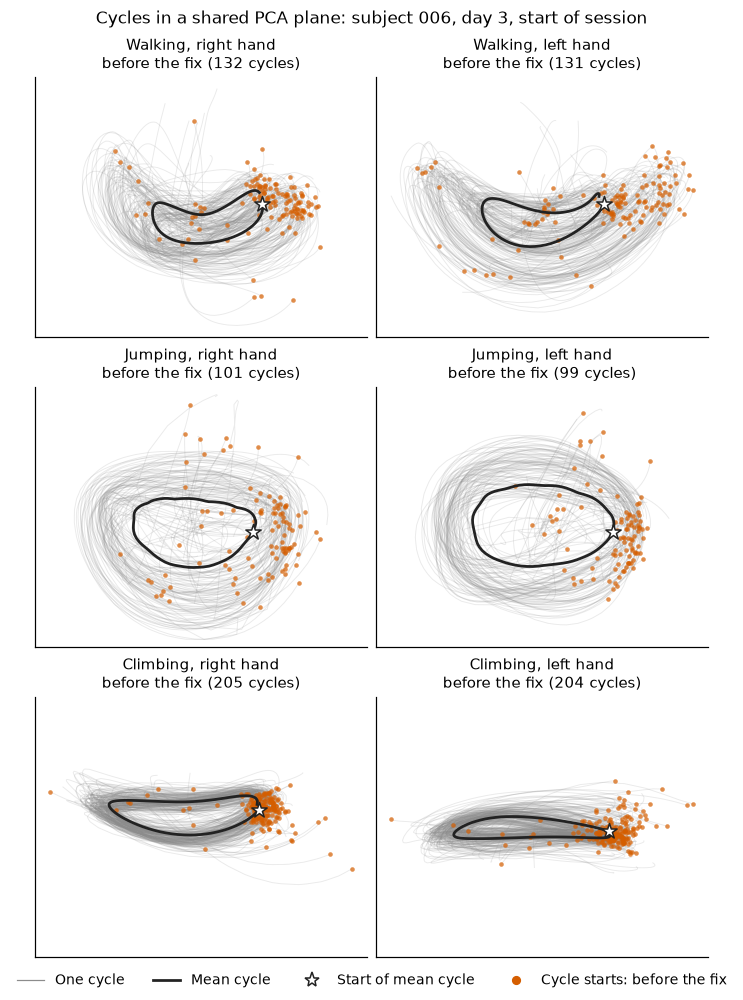

In [3]:
tables, fits = {}, {}
for variant in I.VARIANTS:
    table, fit = I.segment_all(positions, runs, variant)
    tables[variant] = I.add_start_lags(positions, runs, table)
    fits[variant] = fit
    print(f"{variant:34s} {len(table):5d} cycles")

CURRENT = "A. before the fix"
current = tables[CURRENT]
EXAMPLE = dict(subject="006", day=3, part="s")
G.common_plane(positions, runs, {"before the fix": current}, stem="fig01_issue_reproduction", **EXAMPLE);

The picture matches the description in the issue: most starts sit together, some are spread around
the loop, and a few trajectories look nothing like the rest.

## 2. A yardstick that does not depend on any phase estimate

To say how many cycles are misaligned we need a measure that is not itself built from the phase
the package computed. `start_lags` treats each time-normalised 3-D cycle as a closed loop and slides
it along itself until it best matches the mean loop of its condition. The slide that was needed is
the cycle's **start lag**, in degrees of a cycle: 0° means it starts where the others start, ±180°
means it starts half a cycle away. Only the shapes of the cycles are compared.

A cycle is called **misaligned** below when its start lag is more than 45° (an eighth of a cycle).

cycles  misaligned_%  lag_sd_deg
subject skill                                  
002     climb   647.0        12.983      32.853
        jump    619.0        12.439      30.071
        walk    646.0        14.551      38.294
006     climb  2797.0        13.801      32.252
        jump   2463.0        26.431      51.744
        walk   2402.0        18.068      39.409

,cycles,misaligned_%,lag_sd_deg
subject,,,
002,1912.0,13.337,33.901
006,7662.0,19.199,41.134


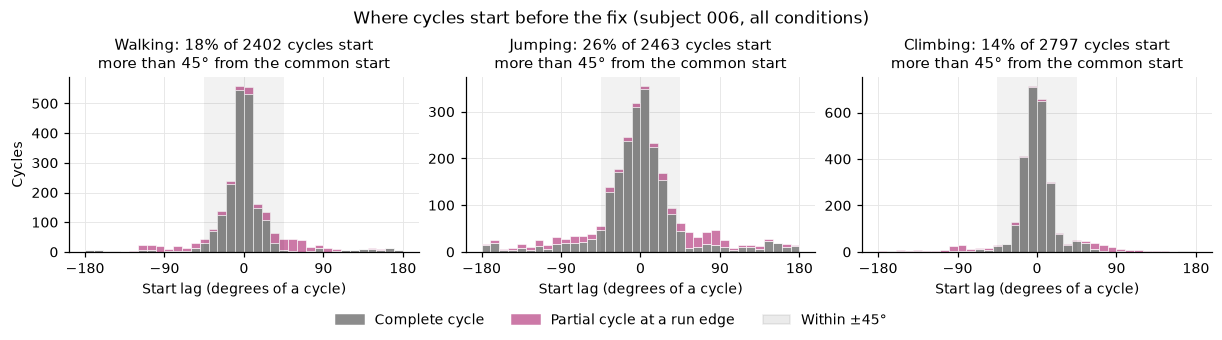

In [4]:
def lag_summary(table):
    lag = table["lag"].dropna()
    return pd.Series({
        "cycles": len(lag),
        "misaligned_%": 100 * (lag.abs() > np.pi / 4).mean(),
        "lag_sd_deg": np.degrees(np.sqrt(-2 * np.log(I.resultant_length(lag)))),
    })

display(current.groupby(["subject", "skill"]).apply(lag_summary, include_groups=False))
display(current.groupby("subject").apply(lag_summary, include_groups=False))
G.start_lag_histograms(current[current["subject"].eq("006")], "fig02_start_lags_current",
                       "Where cycles start before the fix (subject 006, all conditions)");

## 3. Cause 1: partial cycles at the two ends of every run

A run starts and stops wherever the movement classifier switched on and off, which is almost never
at a cycle boundary. Before the fix the package kept the leftover pieces before the first boundary and after the
last one as cycles (any piece of at least 10 samples) with nothing to tell them apart, and reported
their `sample_start` as the first sample of the run. Their start point is wherever the run happened
to begin.

cycles  median duration / run median  misaligned_%
subject complete                                                    
002     False      206.0                         0.593        76.214
        True      1706.0                         1.000         5.744
006     False     1107.0                         0.667        71.635
        True      6555.0                         1.000        10.343

Share of all cycles that are partial: {'002': '10.8%', '006': '14.4%'}
Subject 006: partial cycles account for 54% of the misaligned cycles


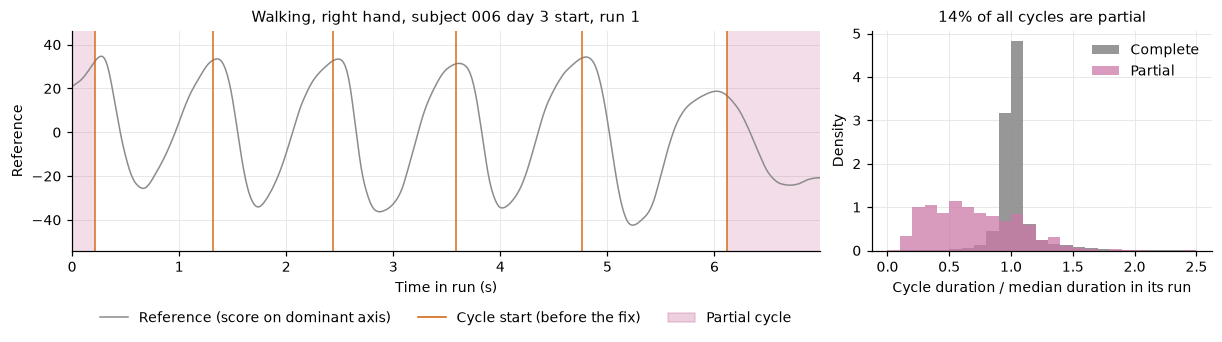

In [5]:
def by_completeness(table):
    lag = table["lag"]
    return pd.Series({
        "cycles": len(table),
        "median duration / run median": table["duration_ratio"].median(),
        "misaligned_%": 100 * (lag.abs() > np.pi / 4).mean(),
    })

summary = current.groupby(["subject", "complete"]).apply(by_completeness, include_groups=False)
display(summary)
share = 1 - current.groupby("subject")["complete"].mean()
print("Share of all cycles that are partial:", {k: f"{100 * v:.1f}%" for k, v in share.items()})
lag = current.loc[current["subject"].eq("006"), "lag"]
partial = ~current.loc[current["subject"].eq("006"), "complete"]
misaligned = lag.abs() > np.pi / 4
print(f"Subject 006: partial cycles account for {100 * (misaligned & partial).sum() / misaligned.sum():.0f}% of the misaligned cycles")

example_run = runs[(runs["subject"] == "006") & (runs["skill"] == "walk") & (runs["day"] == 3) & (runs["part"] == "s")].iloc[0]
example_key = I.run_key(example_run, "r_hand")
G.partial_cycles_example(
    fits[CURRENT][example_key], current[current["subject"].eq("006")], "fig03_partial_cycles",
    f"Walking, right hand, subject 006 day 3 start, run {example_run['movement_run_id']}",
);

## 4. Cause 2: one unreliable sample sets phase zero for a whole run

For the automatic reference the package found the **first** local peak of the band-passed reference
and subtracted the phase at that sample from the entire run. All later boundaries were then the
multiples of 2π counted from that one sample.

The first local peak is the least trustworthy sample in the run. It lies within about one cycle of
the start of the record, where the band-pass filter and the Hilbert transform are still settling,
and `find_peaks` accepts any local maximum however small. If the Hilbert phase at that sample is
not 0, every cycle in the run is shifted by the same amount.

The **anchor error** below is the Hilbert phase at the anchor sample. It should be 0°.

subject,002,006
runs,117.000,665.000
anchor error > 45° (% of runs),5.983,6.767
median |anchor error| (deg),11.436,17.296
between-run SD of start lag (deg),24.794,32.345
within-run SD of start lag (deg),8.934,13.703
between-run SD after removing anchor error (deg),7.726,19.337


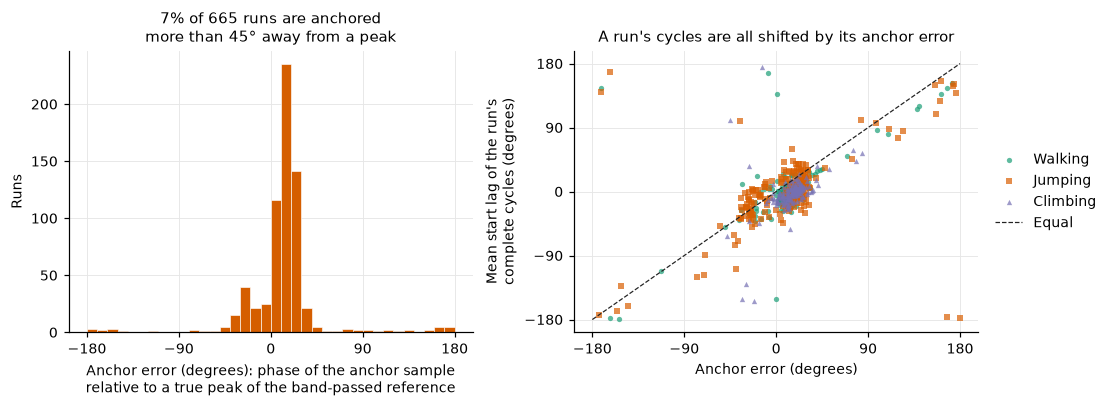

In [6]:
complete_current = I.add_start_lags(positions, runs, tables["B. A + drop partial cycles"].drop(columns="lag"))
run_table = complete_current.groupby(I.RUN_KEYS)["lag"].apply(I.circular_mean).reset_index(name="run_lag")
run_table["within"] = np.nan
run_table["anchor_error"] = [fits[CURRENT][tuple(k)]["anchor_error"] for k in run_table[I.RUN_KEYS].itertuples(index=False)]
run_table["run_lag_deg"] = np.degrees(run_table["run_lag"])
run_table["anchor_error_deg"] = np.degrees(run_table["anchor_error"])

def circular_sd_deg(angle):
    return np.degrees(np.sqrt(-2 * np.log(I.resultant_length(angle))))

run_mean = complete_current.set_index(I.RUN_KEYS).index.map(run_table.set_index(I.RUN_KEYS)["run_lag"])
within = I.wrap(complete_current["lag"].to_numpy() - run_mean.to_numpy())
rows = []
for subject in sorted(run_table["subject"].unique()):
    r = run_table[run_table["subject"].eq(subject)]
    mask = complete_current["subject"].eq(subject).to_numpy() & np.isfinite(within)
    residual = I.wrap(r["run_lag"] - r["anchor_error"])
    rows.append({
        "subject": subject, "runs": len(r),
        "anchor error > 45° (% of runs)": 100 * (r["anchor_error_deg"].abs() > 45).mean(),
        "median |anchor error| (deg)": r["anchor_error_deg"].abs().median(),
        "between-run SD of start lag (deg)": circular_sd_deg(r["run_lag"]),
        "within-run SD of start lag (deg)": circular_sd_deg(within[mask]),
        "between-run SD after removing anchor error (deg)": circular_sd_deg(residual),
    })
display(pd.DataFrame(rows).set_index("subject").T)

G.anchor_statistics(run_table[run_table["subject"].eq("006")], "fig04_anchor_statistics");

Only complete cycles are used here, so this is separate from cause 1. Cycles within one run agree
with each other far better than runs agree with one another, and the run-to-run disagreement is
almost entirely the anchor error: the points lie on the diagonal.

The next figure shows the run with the largest anchor error among the longer runs.

Example run: {'subject': '006', 'skill': 'jump', 'day': np.int64(2), 'part': 's', 'source_file': '006-2-s-j', 'movement_run_id': np.int64(7), 'hand': 'r_hand'}


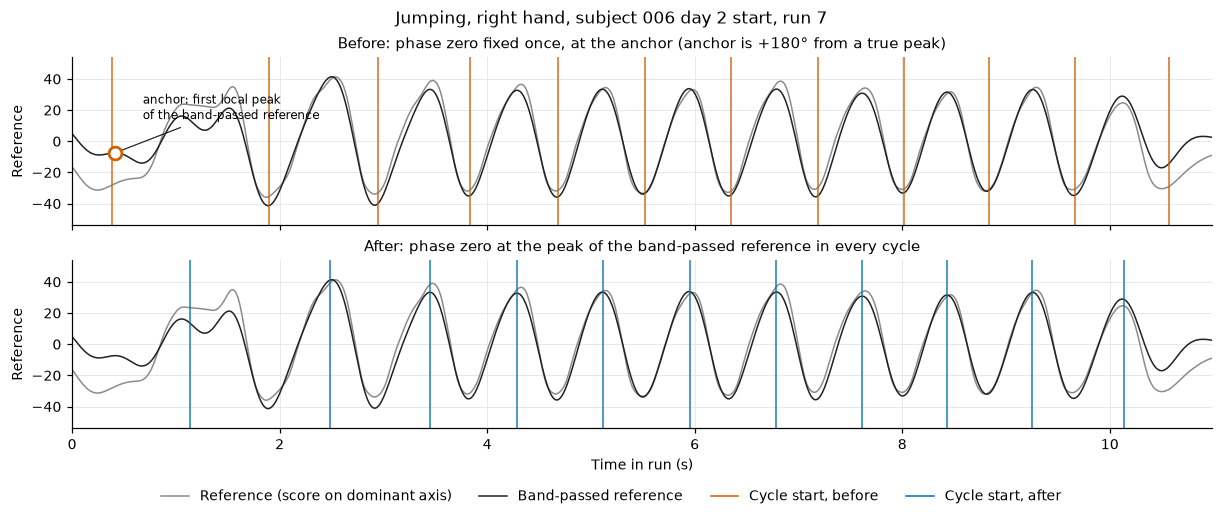

In [7]:
long_runs = run_table[run_table["subject"].eq("006")].copy()
long_runs["n_complete"] = [int(fits[CURRENT][tuple(k)]["cycles"]["complete"].sum()) for k in long_runs[I.RUN_KEYS].itertuples(index=False)]
worst = long_runs[long_runs["n_complete"] >= 8].sort_values("anchor_error_deg", key=np.abs).iloc[-1]
worst_key = tuple(worst[k] for k in I.RUN_KEYS)
print("Example run:", dict(zip(I.RUN_KEYS, worst_key)))
G.anchor_example(
    fits[CURRENT][worst_key], fits["C. B + phase zero at every peak"][worst_key], "fig05_anchor_example",
    f"{G.SKILL_LABELS[worst['skill']]}, {G.HAND_LABELS[worst['hand']].lower()}, subject 006 day {worst['day']} "
    f"{G.PART_LABELS[worst['part']].lower()}, run {worst['movement_run_id']}",
);

## 5. Cause 3: the dominant frequency is estimated separately, and fragilely, for each run

Before the fix the band-pass was centred on the largest periodogram bin of that run's reference, at
any positive frequency. Runs are 3 to about 30 s long. In a short run a slow postural drift can hold more power
than the movement, and the band then follows the drift. The run is cut into one or two very long
"cycles", or into none.

Below, each run's estimate is compared with one frequency estimated from the pooled spectrum of
all runs of the same condition (subject × skill × day × part × hand).

fits  pooled_hz  periodogram_far_from_pooled  robust_far_from_pooled
subject skill                                                                      
002     climb    34      1.128                            4                       1
        jump     44      1.055                            1                       0
        walk     42      0.981                            0                       0
006     climb   186      1.729                           34                      29
        jump    228      1.230                            2                       0
        walk    260      0.923                            3                       2

Run x hand fits with fewer than 2 complete cycles, and total complete cycles:
  C. B + phase zero at every peak     24 of 794 fits    8296 cycles
  D. C + robust frequency              0 of 794 fits    8631 cycles


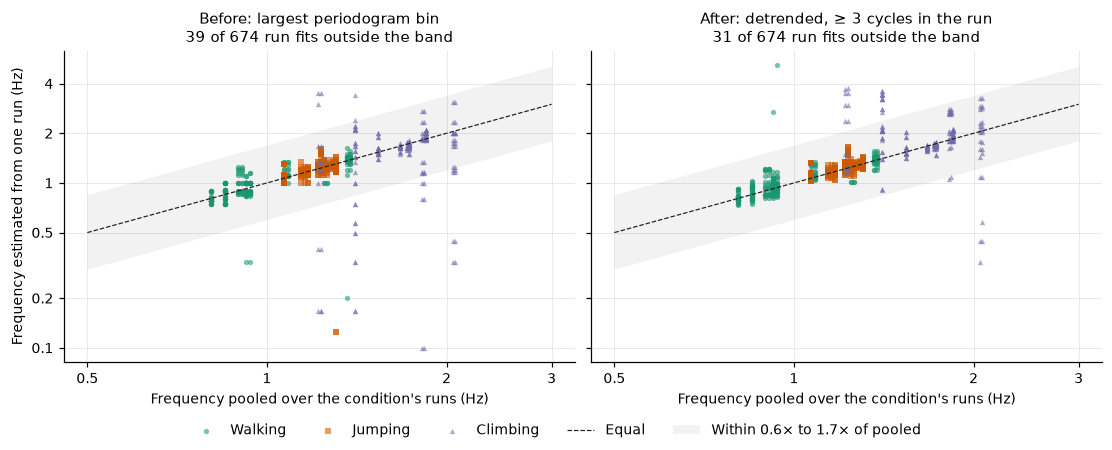

In [8]:
rows = []
for hand in I.HANDS:
    for keys, group in runs.groupby(["subject", "skill", "day", "part"]):
        X_list = [I.run_xyz(positions, run, hand) for _, run in group.iterrows()]
        axis, f_shared = I.shared_reference(X_list)
        for (_, run), X in zip(group.iterrows(), X_list):
            run_axis = I.dominant_axis(X)
            ref = (X - X.mean(axis=0)) @ run_axis
            rows.append({
                **dict(zip(I.RUN_KEYS, I.run_key(run, hand))),
                "duration_s": len(X) / I.FS_HZ,
                "f_periodogram": I.periodogram_frequency(ref),
                "f_robust": I.robust_frequency(ref),
                "f_shared": f_shared,
                "axis_angle_deg": np.degrees(np.arccos(min(1.0, abs(run_axis @ axis)))),
                "axis_flipped": bool(run_axis @ axis < 0),
            })
freq = pd.DataFrame(rows)
for column in ["f_periodogram", "f_robust"]:
    ratio = freq[column] / freq["f_shared"]
    freq[column + "_off"] = (ratio < 0.6) | (ratio > 1.7)
display(freq.groupby(["subject", "skill"]).agg(
    fits=("f_shared", "size"),
    pooled_hz=("f_shared", "median"),
    periodogram_far_from_pooled=("f_periodogram_off", "sum"),
    robust_far_from_pooled=("f_robust_off", "sum"),
))

complete_counts = {
    v: tables[v].groupby(I.RUN_KEYS)["complete"].sum().reindex(pd.MultiIndex.from_frame(freq[I.RUN_KEYS]), fill_value=0)
    for v in ["C. B + phase zero at every peak", "D. C + robust frequency"]
}
print("Run x hand fits with fewer than 2 complete cycles, and total complete cycles:")
for v, counts in complete_counts.items():
    print(f"  {v:34s} {(counts < 2).sum():3d} of {len(counts)} fits   {int(counts.sum()):5d} cycles")

G.frequency_scatter(freq[freq["subject"].eq("006")], "fig06_frequency_per_run");

Example run: {'subject': '006', 'skill': 'walk', 'day': np.int64(3), 'part': 'e', 'source_file': '006-3-e-w', 'movement_run_id': np.int64(12), 'hand': 'r_hand'}


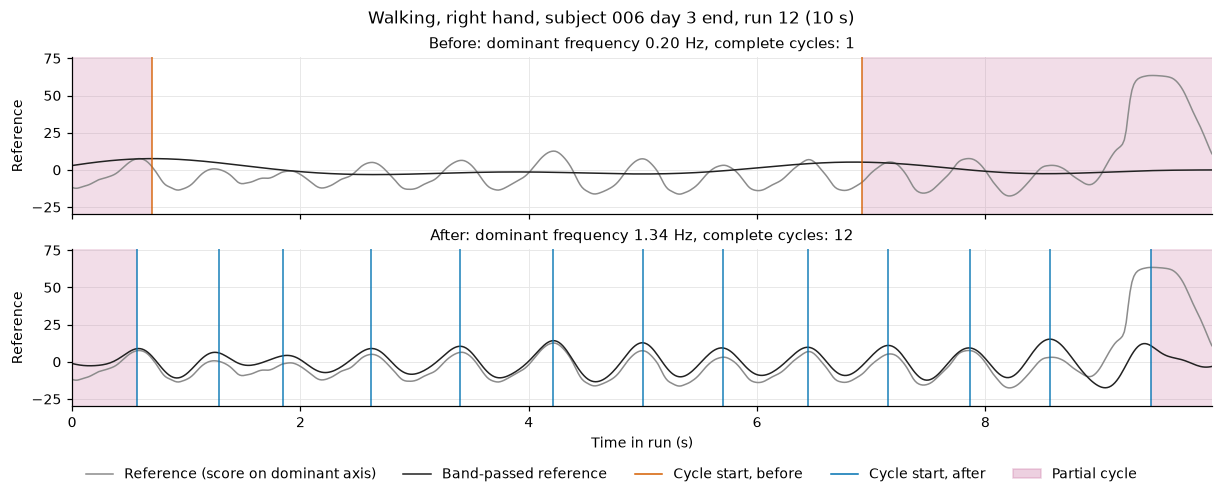

In [9]:
candidates = freq[freq["subject"].eq("006") & freq["f_periodogram_off"] & ~freq["f_robust_off"]]
pick = candidates.sort_values("duration_s").iloc[-1]
pick_key = tuple(pick[k] for k in I.RUN_KEYS)
print("Example run:", dict(zip(I.RUN_KEYS, pick_key)))
G.frequency_example(
    fits["C. B + phase zero at every peak"][pick_key], fits["D. C + robust frequency"][pick_key], "fig07_frequency_example",
    f"{G.SKILL_LABELS[pick['skill']]}, {G.HAND_LABELS[pick['hand']].lower()}, subject 006 day {pick['day']} "
    f"{G.PART_LABELS[pick['part']].lower()}, run {pick['movement_run_id']} ({pick['duration_s']:.0f} s)",
);

The new per-run rule (detrend, and only consider frequencies that fit at least three cycles
into the run) removes the drift cases, and with them almost all runs that produced no usable cycles.

It does not make every run agree with the pooled frequency. The disagreements that remain are all in
subject 006's climbing, and section 7b shows that there the pooled frequency is the less reliable
of the two, so they are not counted as errors of the per-run rule.

## 6. Two smaller effects

**Cycles that are not one block of samples.** A cycle is "all samples whose phase lies in
[2πk, 2π(k+1))". When the phase briefly runs backwards across a boundary, a few samples of the next
cycle are assigned back to the previous one. `sample_start`..`sample_stop` then overlaps the
neighbouring cycle.

**Direction of the reference axis.** The sign of the axis is fixed by its Y component. When the
dominant axis is close to horizontal that component is near zero and its sign can differ between
runs, which moves phase zero by half a cycle.

In [10]:
display(pd.DataFrame({
    "cycles": current.groupby("subject").size(),
    "not contiguous": (~current["contiguous"]).groupby(current["subject"]).sum(),
    "run fits": freq.groupby("subject").size(),
    "axis flipped vs condition": freq.groupby("subject")["axis_flipped"].sum(),
    "axis > 30° from condition": (freq["axis_angle_deg"] > 30).groupby(freq["subject"]).sum(),
}))
display(freq.groupby(["subject", "skill"])["axis_angle_deg"].quantile([0.5, 0.9]).unstack().rename(
    columns={0.5: "median axis angle (deg)", 0.9: "90th percentile (deg)"}))

,cycles,not contiguous,run fits,axis flipped vs condition,axis > 30° from condition
subject,,,,,
002,1912,9,120,0,1
006,7662,105,674,2,44


median axis angle (deg)  90th percentile (deg)
subject skill                                                
002     climb                    5.692                  9.514
        jump                    12.964                 22.898
        walk                     7.364                 14.579
006     climb                    6.356                 13.773
        jump                    13.406                 27.870
        walk                    10.356                 25.867

## 7. The fix, one change at a time

D is the package on this branch called as before. E is the same package with `ref_axis=` set to
`dominant_reference_axis(runs_of_the_condition)`.

| | Change |
|---|---|
| **A** | The package before the fix. |
| **B** | A, keeping only complete cycles. |
| **C** | B, with phase zero at the peak of the band-passed reference in **every** cycle (the Hilbert phase as it is, no single anchor), and each cycle forced to be one block of samples. |
| **D** | C, with the more robust per-run frequency estimate. |
| **E** | D, but the reference axis is estimated once per condition and shared by its runs. The frequency is still estimated per run. |

Three measures, none of which uses a phase estimate: the share of misaligned cycles, the spread of
start lags, and Noam's cycle-variability measure (RMS deviation of each time-normalised hand-Y cycle
from the condition's mean cycle, divided by the cycle amplitude).

cycles  misaligned (%)  start-lag SD (deg)  hand-Y variability  start-point scatter  odd duration (%)
subject variant                                                                                                                               
002     A. before the fix                  1912          11.190              29.600               0.134                0.763             7.033
        B. A + drop partial cycles         1706           1.027              15.730               0.107                0.523             0.000
        C. B + phase zero at every peak    1709           0.748              10.569               0.098                0.479             0.000
        D. C + robust frequency            1748           0.748              10.477               0.100                0.509             0.000
        E. D + shared axis                 1749           0.746               9.112               0.093                0.502             0.000
006     A. before the fix                  7662          18.961              40.113               0.182                0.829             8.969
        B. A + drop partial cycles         6555           8.869              29.815               0.138                0.719             1.190
        C. B + phase zero at every peak    6587           2.401              15.546               0.103                0.532             0.935
        D. C + robust frequency            6883           2.596              15.861               0.103                0.535             1.124
        E. D + shared axis                 6895           1.860              12.709               0.094                0.498             0.931

Misaligned cycles, all cycles pooled (%):


subject,002,006
A. before the fix,13.337,19.199
B. A + drop partial cycles,5.862,10.145
C. B + phase zero at every peak,0.702,3.431
D. C + robust frequency,1.087,3.443
E. D + shared axis,1.086,2.292


misaligned                 lag_sd_deg                 shape_rms              
skill                                climb    jump    walk      climb    jump    walk     climb   jump   walk
variant                                                                                                      
A. before the fix                   15.351  27.932  17.725     33.547  52.213  35.572     0.154  0.204  0.160
B. A + drop partial cycles           5.202  18.781   7.742     22.497  44.281  23.455     0.127  0.173  0.122
C. B + phase zero at every peak      0.843   3.871   1.246     10.193  18.843  12.208     0.083  0.106  0.092
D. C + robust frequency              0.843   3.871   1.607     10.523  18.807  13.582     0.082  0.107  0.095
E. D + shared axis                   0.843   3.060   1.000     10.384  13.916  11.041     0.083  0.098  0.093

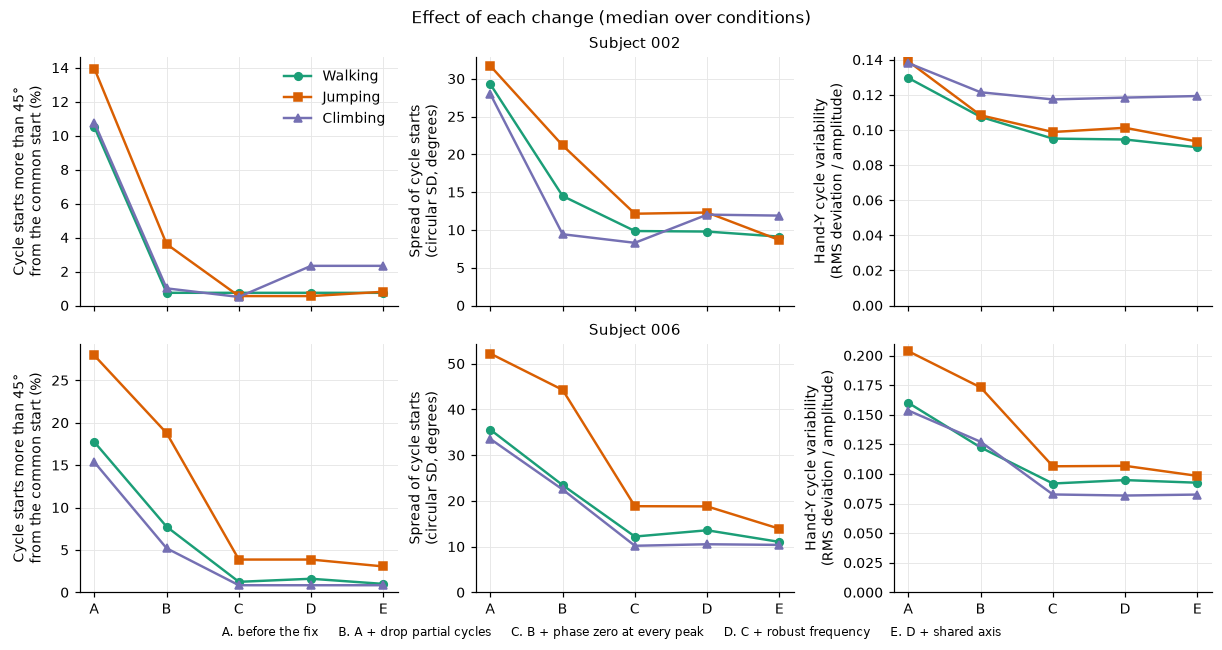

In [11]:
metrics = pd.concat([
    I.condition_metrics(positions, runs, tables[v]).assign(variant=v) for v in I.VARIANTS
], ignore_index=True)

columns = ["misaligned", "lag_sd_deg", "shape_rms", "start_scatter", "odd_duration"]
overall = metrics.groupby(["subject", "variant"])[columns].median()
overall.insert(0, "cycles", [len(tables[v][tables[v]["subject"].eq(s)]) for s, v in overall.index])
overall["misaligned"] *= 100
overall["odd_duration"] *= 100
display(overall.rename(columns={
    "misaligned": "misaligned (%)", "lag_sd_deg": "start-lag SD (deg)",
    "shape_rms": "hand-Y variability", "start_scatter": "start-point scatter",
    "odd_duration": "odd duration (%)",
}))

pooled = pd.DataFrame({
    v: tables[v].groupby("subject")["lag"].apply(lambda lag: 100 * (lag.dropna().abs() > np.pi / 4).mean())
    for v in I.VARIANTS
}).T
print("Misaligned cycles, all cycles pooled (%):")
display(pooled)

by_skill = metrics[metrics["subject"].eq("006")].groupby(["skill", "variant"])[["misaligned", "lag_sd_deg", "shape_rms"]].median()
by_skill["misaligned"] *= 100
display(by_skill.unstack("skill"))
G.fix_steps(metrics, "fig08_fix_steps");

### 7b. Share the axis, not the frequency

It is tempting to share the dominant frequency across a condition's runs as well. That was tried
and is not recommended. It changes nothing where the movement is stable, and it makes early
climbing worse: on day 1 subject 006's climbing tempo differs from run to run, and a single pooled
frequency fits none of them well.

In [12]:
rejected, _ = I.segment_all(positions, runs, "E + shared frequency")
compare = pd.concat([
    I.condition_metrics(positions, runs, tables["E. D + shared axis"]).assign(variant="E. shared axis"),
    I.condition_metrics(positions, runs, rejected).assign(variant="E + shared frequency"),
])
climb = compare[compare["subject"].eq("006") & compare["skill"].eq("climb")]
table = climb.groupby(["day", "variant"])[["misaligned", "lag_sd_deg", "shape_rms"]].median()
table["misaligned"] *= 100
display(table.unstack("variant").rename(columns={"misaligned": "misaligned (%)", "lag_sd_deg": "start-lag SD (deg)", "shape_rms": "hand-Y variability"}))
other = compare[~(compare["subject"].eq("006") & compare["skill"].eq("climb"))]
print("All other subject x skill combinations (median over conditions):")
display(other.groupby("variant")[["misaligned", "lag_sd_deg", "shape_rms"]].median())

misaligned (%)                  start-lag SD (deg)                  hand-Y variability               
variant E + shared frequency E. shared axis E + shared frequency E. shared axis E + shared frequency E. shared axis
day                                                                                                                
1                      12.66          3.855               35.856         20.149                0.252          0.165
2                       0.68          0.316                8.912          8.801                0.064          0.063
3                       0.00          0.562                7.048          8.618                0.073          0.072

All other subject x skill combinations (median over conditions):


,misaligned,lag_sd_deg,shape_rms
variant,,,
E + shared frequency,0.013,11.765,0.094
E. shared axis,0.016,12.460,0.095


## 8. Before and after, in the views used in the issue

The same condition as in section 1, before the fix next to after it (variant E).
Note the mean cycle as well as the start points: averaging misaligned cycles shrinks and distorts it.

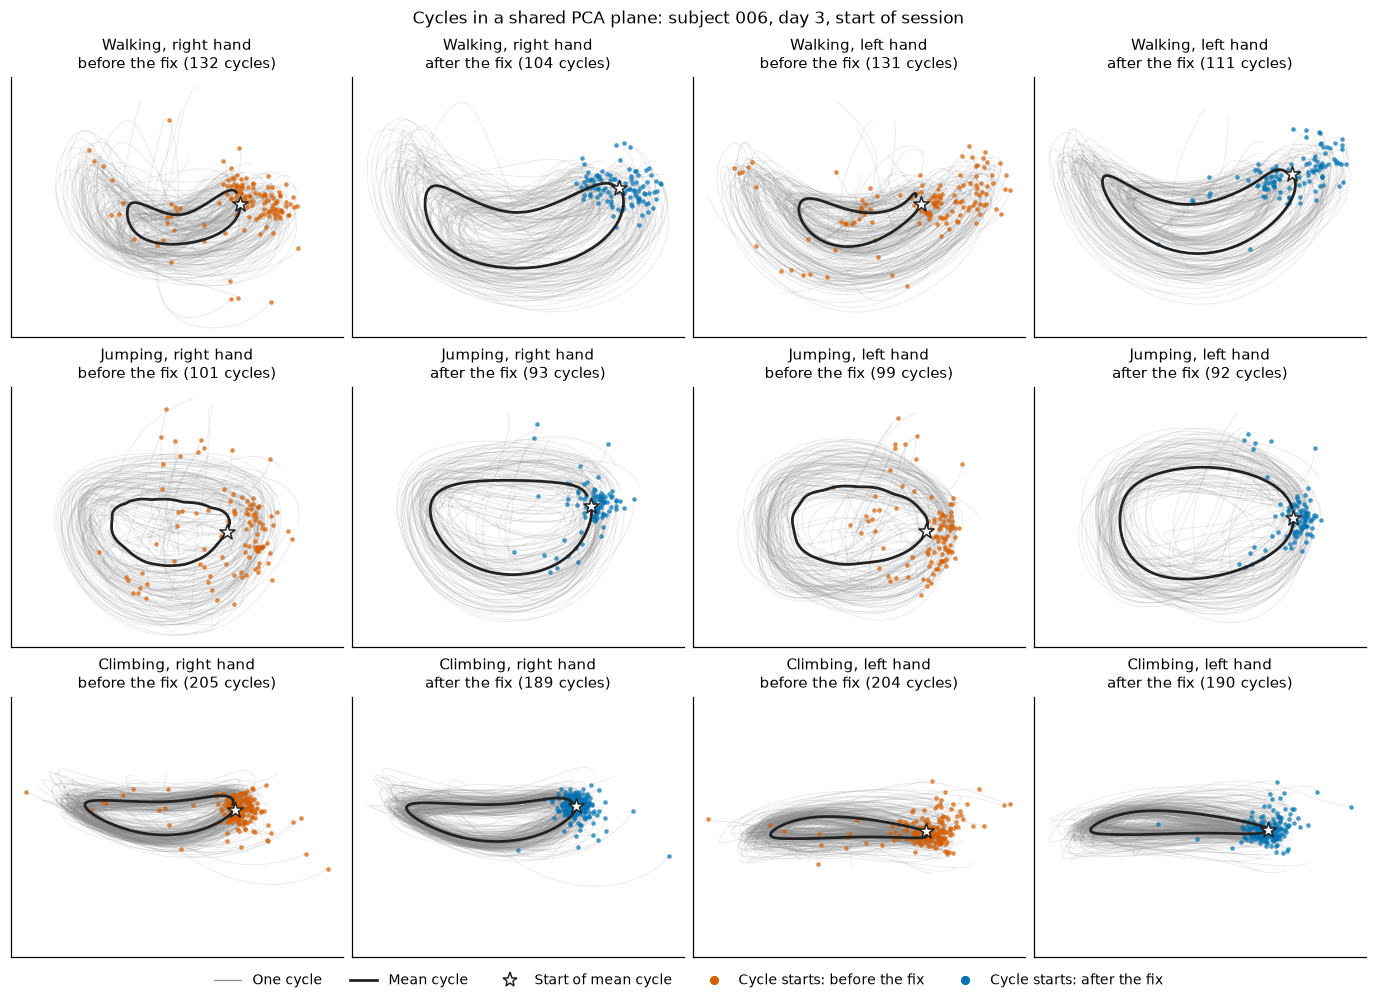

In [13]:
PROPOSED = "E. D + shared axis"
pair = {"before the fix": current, "after the fix": tables[PROPOSED]}
G.common_plane(positions, runs, pair, stem="fig09_before_after_common_plane", **EXAMPLE);

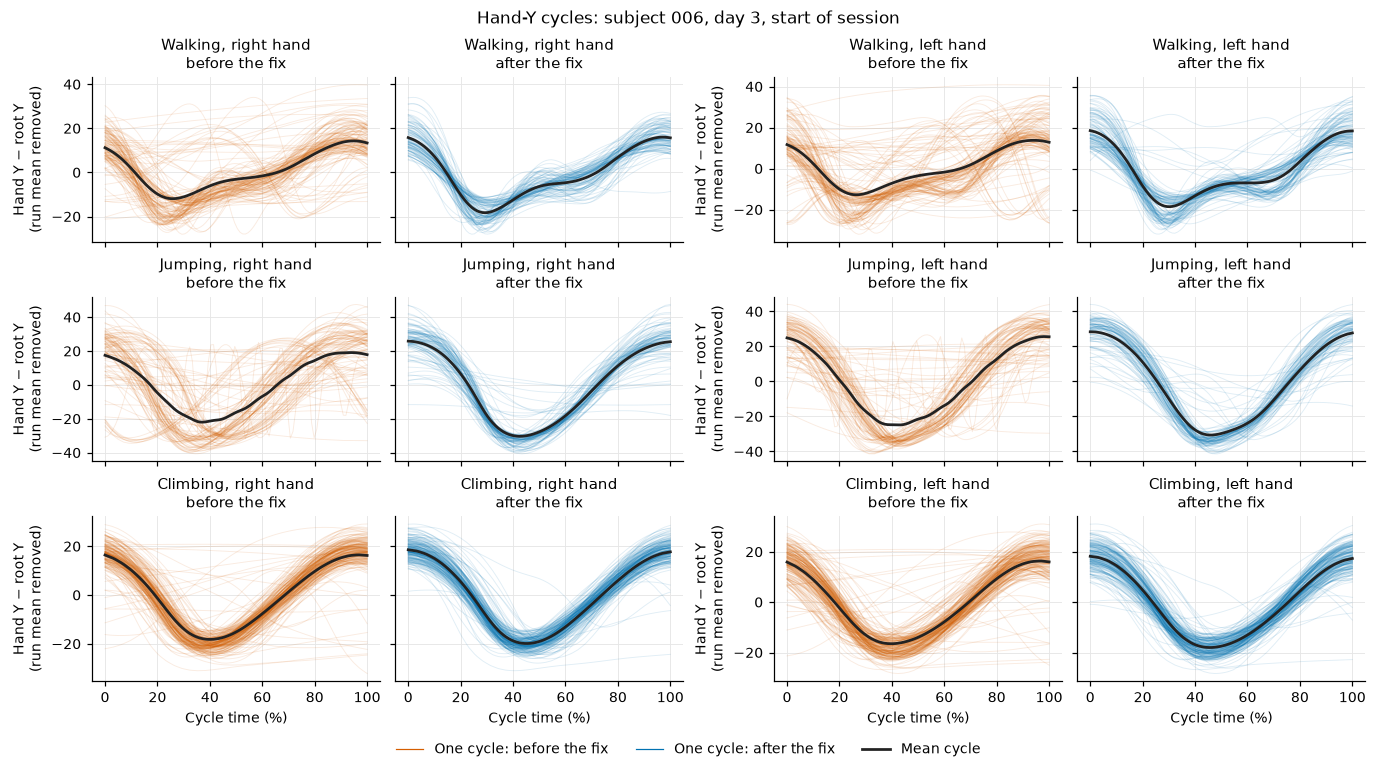

In [14]:
G.hand_y_cycles(positions, runs, pair, stem="fig10_before_after_hand_y", **EXAMPLE);

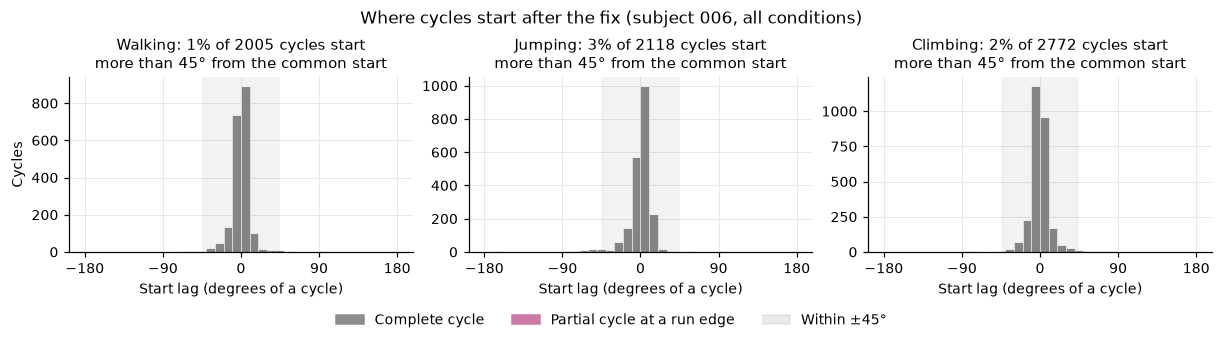

In [15]:
G.start_lag_histograms(tables[PROPOSED][tables[PROPOSED]["subject"].eq("006")], "fig11_start_lags_proposed",
                       "Where cycles start after the fix (subject 006, all conditions)");

## 9. What is left, and how to screen for it

After the fix a small share of cycles is still misaligned. These are stretches where the movement
itself is irregular: a pause, a stumble, a change of tempo. The package now reports per-cycle
quantities that find them:

- `duration_ratio`: cycle duration divided by the median duration of complete cycles in the run;
- `amplitude_ratio`: mean Hilbert amplitude in the cycle divided by the run median;
- `backward_steps`: number of samples in the cycle where the phase ran backwards.

The screen used below flags a cycle when its duration ratio is outside 0.6 to 1.5, its amplitude
ratio is below 0.5, or its phase ran backwards at least once.

In [16]:
proposed = tables[PROPOSED].dropna(subset=["lag"]).copy()
proposed["flagged"] = I.qc_flag(proposed)
proposed["misaligned"] = proposed["lag"].abs() > np.pi / 4

def screen(table):
    flagged, bad = table["flagged"], table["misaligned"]
    return pd.Series({
        "cycles": len(table),
        "flagged (%)": 100 * flagged.mean(),
        "misaligned among flagged (%)": 100 * bad[flagged].mean(),
        "misaligned among unflagged (%)": 100 * bad[~flagged].mean(),
        "misaligned cycles caught by the flag (%)": 100 * (bad & flagged).sum() / max(bad.sum(), 1),
    })

display(proposed.groupby("subject").apply(screen, include_groups=False))
display(proposed[proposed["subject"].eq("006")].groupby("skill").apply(screen, include_groups=False))

,cycles,flagged (%),misaligned among flagged (%),misaligned among unflagged (%),misaligned cycles caught by the flag (%)
subject,,,,,
002,1749.0,1.144,25.000,0.810,26.316
006,6895.0,5.729,32.405,0.462,81.013


,cycles,flagged (%),misaligned among flagged (%),misaligned among unflagged (%),misaligned cycles caught by the flag (%)
skill,,,,,
climb,2772.0,6.602,26.776,0.309,85.965
jump,2118.0,5.855,49.194,0.502,85.915
walk,2005.0,4.389,20.455,0.626,60.000


## 10. The workaround for the package before the fix

`fit_with_absolute_phase_zero` was written to get changes B and C out of the package at `d83b30d`
using public functions only: compute the Hilbert phase of the automatic reference, trim the run to
start and end on a peak, and pass that phase in with `phase=`. It is not needed on this branch.
The cell below checks that it still returns the same cycle starts as the package now does.

In [17]:
checked = differing = too_short = 0
for _, run in runs.iterrows():
    for hand in I.HANDS:
        X = I.run_xyz(positions, run, hand)
        try:
            samples, cycles, details, offset = I.fit_with_absolute_phase_zero(X)
        except ValueError:
            too_short += 1
            continue
        _, package, _ = I.package_cycles(X)
        interior = package[(package["sample_start"] > 0) & (package["sample_stop"] < len(X))]
        got = (cycles["sample_start"] + offset).to_numpy()
        checked += 1
        differing += not (len(got) == len(interior) and (got == interior["sample_start"].to_numpy()).all())
print(f"{checked} fits checked, {differing} differ from the package, {too_short} runs had fewer than one complete cycle")
assert differing == 0

794 fits checked, 0 differ from the package, 0 runs had fewer than one complete cycle
